#Install/check Tensorflow 2

In [ ]:
import tensorflow as tf
print("GPU Available: ", tf.test.is_gpu_available())

print("Tensorflow Version: ", tf.__version__)
print("Keras Version: ", tf.keras.__version__)

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.
GPU Available:  True
Tensorflow Version:  2.4.1
Keras Version:  2.4.0


If the GPU is not available, open Runtime -> Change runtime type and make sure that GPU is selected. Sometimes the GPU is still not available, you need to open Runtime -> reset all runtimes, then try again

In [ ]:
from __future__ import absolute_import, division, print_function, unicode_literals
print("Keras Version: ", tf.keras.__version__)

Keras Version:  2.4.0


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
#check GPU
physical_devices = tf.config.experimental.list_physical_devices('GPU')
print(physical_devices)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [1]:
! nvidia-smi

Mon May 10 18:51:13 2021       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 465.19.01    Driver Version: 460.32.03    CUDA Version: 11.2     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla V100-SXM2...  Off  | 00000000:00:04.0 Off |                    0 |
| N/A   35C    P0    25W / 300W |      0MiB / 16160MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

# Connect to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
!ls /content/gdrive/MyDrive/'Colab Notebooks'/Kaggle

casting_data  m5-forecasting-accuracy.zip  mymodel0.h5	 traininghistory.pdf
kaggle.json   model_finetune.zip	   saved_models


*4*/4wHzvFUjSY5DzzeDHN6ZYeeeLJBFHs_-rMqB5Bsim793_O_kutnNM1Y

In [ ]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = "/content/gdrive/MyDrive/Colab Notebooks/Kaggle"

# Load Kaggle Data

In [ ]:
!pip install kaggle

In [ ]:
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

 98% 600M/612M [00:08<00:00, 57.9MB/s]
100% 612M/612M [00:09<00:00, 71.0MB/s]


In [ ]:
!kaggle config view #View current config values

Configuration values from /content/gdrive/MyDrive/Colab Notebooks/Kaggle
- username: lkk688
- path: /content
- proxy: None
- competition: None


In [ ]:
!kaggle config set -n path -v /content

- path is now set to: /content


In [ ]:
#changing the working directory
%cd /content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
!pwd
!ls

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
gtsrb-german-traffic-sign.zip


In [ ]:
!unzip gtsrb-german-traffic-sign.zip

Streaming output truncated to the last 5000 lines.
  inflating: train/5/00005_00053_00010.png  
  inflating: train/5/00005_00053_00011.png  
  inflating: train/5/00005_00053_00012.png  
  inflating: train/5/00005_00053_00013.png  
  inflating: train/5/00005_00053_00014.png  
  inflating: train/5/00005_00053_00015.png  
  inflating: train/5/00005_00053_00016.png  
  inflating: train/5/00005_00053_00017.png  
  inflating: train/5/00005_00053_00018.png  
  inflating: train/5/00005_00053_00019.png  
  inflating: train/5/00005_00053_00020.png  
  inflating: train/5/00005_00053_00021.png  
  inflating: train/5/00005_00053_00022.png  
  inflating: train/5/00005_00053_00023.png  
  inflating: train/5/00005_00053_00024.png  
  inflating: train/5/00005_00053_00025.png  
  inflating: train/5/00005_00053_00026.png  
  inflating: train/5/00005_00053_00027.png  
  inflating: train/5/00005_00053_00028.png  
  inflating: train/5/00005_00053_00029.png  
  inflating: train/5/00005_00054_00000.png  
  in

In [ ]:
os.chdir('/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign')
!ls 

gtsrb-german-traffic-sign.zip  Meta	 test  Test.csv  Train
meta			       Meta.csv  Test  train	 Train.csv


In [ ]:
train_df = pd.read_csv('Train.csv')
# display a sneak peek of the data
train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [ ]:
print(f'Number of classes: {train_df.ClassId.unique().shape[0]}')


Number of classes: 43


In [ ]:
labels = ['20 km/h', '30 km/h', '50 km/h', '60 km/h', '70 km/h', '80 km/h', '80 km/h end', '100 km/h', '120 km/h', 'No overtaking',
               'No overtaking for trucks', 'Crossroad with secondary way', 'Main road', 'Give way', 'Stop', 'Road up', 'Road up for truck', 'No entry',
               'Other dangerous', 'Turn left', 'Turn right', 'Winding road', 'Hollow road', 'Slippery road', 'Narrowing road', 'Roadwork', 'Traffic light',
               'Pedestrian', 'Children', 'Bike', 'Snow', 'Deer', 'End of the limits', 'Only right', 'Only left', 'Only straight', 'Only straight and right', 
               'Only straight and left', 'Take right', 'Take left', 'Circle crossroad', 'End of overtaking limit', 'End of overtaking limit for truck']


In [ ]:
# add column with readable labels
train_df['Label'] = train_df['ClassId'].replace(sorted(train_df['ClassId'].unique()), labels)
# print updated df
train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Label
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,Turn right
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,Turn right
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,Turn right
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,Turn right
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,Turn right


## load these images off disk using image_dataset_from_directory
https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory
Old solution: Use ImageDataGenerator to rescale the images: https://keras.io/preprocessing/image/

In [ ]:
base_dir = '/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train'
print(base_dir)

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train


In [ ]:
batch_size = 32
img_height = 28 #180
img_width = 28 #180

In [ ]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 31368 files for training.


In [ ]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 7841 files for validation.


In [ ]:
class_names = train_ds.class_names
print(class_names)

['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9']


In [ ]:
labels = ['Speed Limit (20Km/H)', 'Speed Limit (30Km/H)','No Passing For Vechiles Over 3.5 Metric Tons','Right-Of-Way At The Next Intersection', 'Priority Road', 'Yield', 'Stop', 'No Vechiles', 'Vechiles Over 3.5 Metric Tons Prohibited', 'No Entry',
 'General Caution', 'Dangerous Curve To The Left', 'Speed Limit (50Km/H)',
 'Dangerous Curve To The Right', 'Double Curve', 'Bumpy Road',
 'Slippery Road', 'Road Narrows On The Right', 'Road Work', 'Traffic Signals',
 'Pedestrians', 'Children Crossing', 'Bicycles Crossing',
 'Speed Limit (60Km/H)', 'Beware Of Ice/Snow', 'Wild Animals Crossing',
 'End Of All Speed And Passing Limits', 'Turn Right Ahead',
 'Turn Left Ahead', 'Ahead Only', 'Go Straight Or Right',
 'Go Straight Or Left', 'Keep Right', 'Keep Left', 'Speed Limit (70Km/H)',
 'Roundabout Mandatory', 'End Of No Passing',
 'End Of No Passing By Vechiles Over 3.5 Metric Tons',
 'Speed Limit (80Km/H)', 'End Of Speed Limit (80Km/H)',
 'Speed Limit (100Km/H)', 'Speed Limit (120Km/H)', 'No Passing']

In [ ]:
len(labels)

43

In [ ]:
labels[int(class_names[0])] # convert to label

'20 km/h'

38
12
40
37
40
12
8
29
5


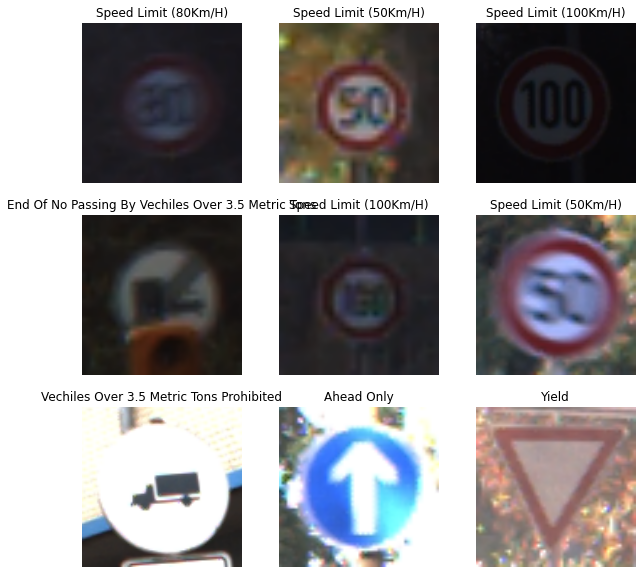

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, groundlabels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    classid=groundlabels[i].numpy()
    print(classid)
    plt.title(labels[classid])
    plt.axis("off")

In [ ]:
#manually iterate over the dataset and retrieve batches of images:
#This is a batch of 32 images of shape 180x180x3 (the last dimension referes to color channels RGB). The label_batch is a tensor of the shape (32,), these are corresponding labels to the 32 images.
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 28, 28, 3)
(32,)


In [ ]:
image_batch

<tf.Tensor: shape=(32, 28, 28, 3), dtype=float32, numpy=
array([[[[103.61607 ,  93.42857 ,  81.459816],
         [ 93.55357 , 109.79464 , 109.30357 ],
         [140.75446 , 117.55357 , 116.5759  ],
         ...,
         [ 67.49552 ,  57.71874 ,  45.013386],
         [ 79.553566,  68.848206,  51.303574],
         [ 87.102684,  80.04912 ,  55.29018 ]],

        [[ 96.72768 , 113.4375  , 104.28572 ],
         [ 69.90179 ,  87.01785 ,  88.03571 ],
         [172.52232 , 151.64285 , 150.34375 ],
         ...,
         [ 72.79463 ,  59.01339 ,  42.3125  ],
         [ 77.56697 ,  62.852676,  41.638397],
         [ 95.28126 ,  83.75    ,  59.3884  ]],

        [[173.35268 , 155.15625 , 147.5982  ],
         [135.05803 , 103.4241  ,  97.06696 ],
         [113.803566, 124.58035 , 115.21875 ],
         ...,
         [ 80.70088 ,  71.13839 ,  50.000004],
         [ 80.566986,  65.13394 ,  36.35717 ],
         [ 76.28125 ,  64.9375  ,  42.544647]],

        ...,

        [[ 59.450893,  51.245537,  

In [ ]:
#Standardize the data, standardize values [0, 255] to be in the [0, 1]
from tensorflow.keras import layers

normalization_layer = tf.keras.layers.experimental.preprocessing.Rescaling(1./255)

#There are two ways to use this layer. You can apply it to the dataset by calling map:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixels values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.031257536 0.40103042


## Train a model

In [ ]:
#Configure the dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
num_classes = len(class_names)
num_classes

43

In [ ]:
model = tf.keras.Sequential([
  #layers.experimental.preprocessing.Rescaling(1./255),
  layers.Conv2D(32, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

In [ ]:
model.compile(
  optimizer='adam',
  loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
  metrics=['accuracy'])

In [ ]:
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=20
)

Epoch 1/20
981/981 [==============================] - 19s 15ms/step - loss: 4.0212 - accuracy: 0.2494 - val_loss: 1.0160 - val_accuracy: 0.7148
Epoch 2/20
981/981 [==============================] - 3s 3ms/step - loss: 0.7914 - accuracy: 0.7689 - val_loss: 0.4943 - val_accuracy: 0.8683
Epoch 3/20
981/981 [==============================] - 3s 3ms/step - loss: 0.4002 - accuracy: 0.8893 - val_loss: 0.3191 - val_accuracy: 0.9237
Epoch 4/20
981/981 [==============================] - 3s 3ms/step - loss: 0.3008 - accuracy: 0.9168 - val_loss: 0.3722 - val_accuracy: 0.9043
Epoch 5/20
981/981 [==============================] - 3s 3ms/step - loss: 0.2245 - accuracy: 0.9412 - val_loss: 0.2935 - val_accuracy: 0.9325
Epoch 6/20
981/981 [==============================] - 3s 3ms/step - loss: 0.1920 - accuracy: 0.9517 - val_loss: 0.2509 - val_accuracy: 0.9410
Epoch 7/20
981/981 [==============================] - 3s 3ms/step - loss: 0.1895 - accuracy: 0.9506 - val_loss: 0.2934 - val_accuracy: 0.9370
Epoc

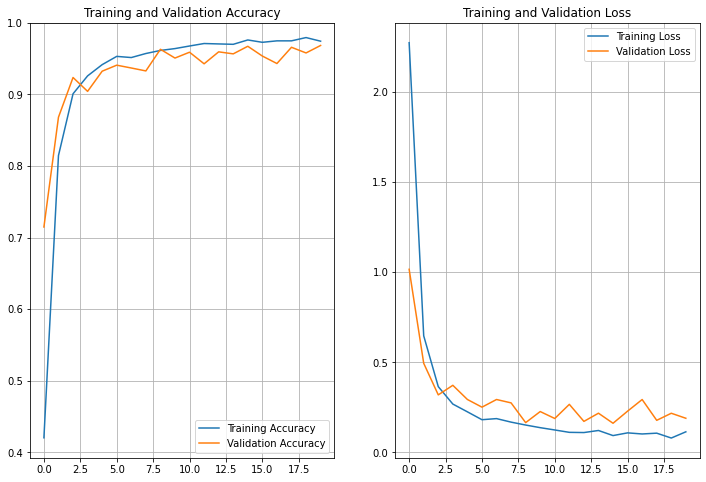

In [ ]:
def plot_history(history, metric, val_metric):
  acc = history.history[metric]
  val_acc = history.history[val_metric]

  loss=history.history['loss']
  val_loss=history.history['val_loss']

  epochs_range = range(len(acc))

  fig=plt.figure(figsize=(12, 8))
  plt.subplot(1, 2, 1)
  plt.plot(epochs_range, acc, label='Training Accuracy')
  plt.plot(epochs_range, val_acc, label='Validation Accuracy')
  plt.legend(loc='lower right')
  plt.ylim([min(plt.ylim()),1])
  plt.grid(True)
  plt.title('Training and Validation Accuracy')

  plt.subplot(1, 2, 2)
  plt.plot(epochs_range, loss, label='Training Loss')
  plt.plot(epochs_range, val_loss, label='Validation Loss')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.title('Training and Validation Loss')
  plt.show()
  fig.savefig('traininghistory.pdf')

plot_history(history, 'accuracy', 'val_accuracy')

# Model2 Transfer learning

In [ ]:
base_dir = '/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train'
print(base_dir)

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train


In [ ]:
batch_size = 32
img_height = 160 #180
img_width = 160 #180

In [ ]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 31368 files for training.


In [ ]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 7841 files for validation.


In [ ]:
class_names = train_ds.class_names
print(class_names)

['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9']


In [ ]:
labels = ['20 km/h', '30 km/h', '50 km/h', '60 km/h', '70 km/h', '80 km/h', '80 km/h end', '100 km/h', '120 km/h', 'No overtaking',
               'No overtaking for trucks', 'Crossroad with secondary way', 'Main road', 'Give way', 'Stop', 'Road up', 'Road up for truck', 'No entry',
               'Other dangerous', 'Turn left', 'Turn right', 'Winding road', 'Hollow road', 'Slippery road', 'Narrowing road', 'Roadwork', 'Traffic light',
               'Pedestrian', 'Children', 'Bike', 'Snow', 'Deer', 'End of the limits', 'Only right', 'Only left', 'Only straight', 'Only straight and right', 
               'Only straight and left', 'Take right', 'Take left', 'Circle crossroad', 'End of overtaking limit', 'End of overtaking limit for truck']

In [ ]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.experimental.preprocessing.RandomFlip('horizontal'),
  tf.keras.layers.experimental.preprocessing.RandomRotation(0.2),
])

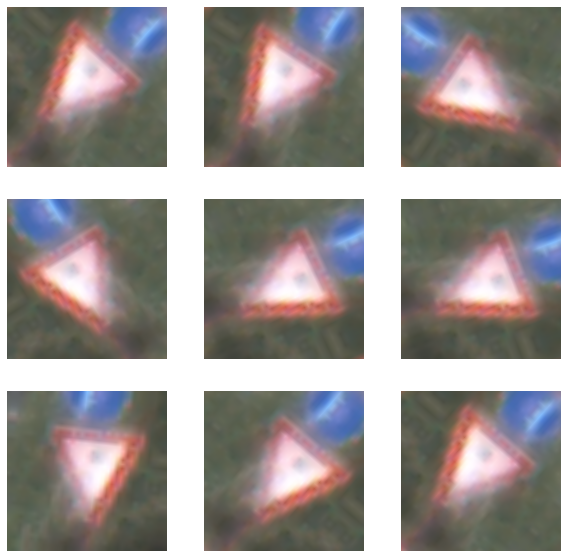

In [ ]:
for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [ ]:
#tf.keras.applications.MobileNetV2 for use as your base model, This model expects pixel vaues in [-1,1]
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [ ]:
# Create the base model from the pre-trained model MobileNet V2
IMG_SIZE = (img_height, img_width)
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

9412608/9406464 [==============================] - 0s 0us/step


In [ ]:
IMG_SHAPE

(160, 160, 3)

In [ ]:
image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 5, 5, 1280)


In [ ]:
base_model.trainable = False

In [ ]:
# Let's take a look at the base model architecture
base_model.summary()

Model: "mobilenetv2_1.00_160"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 160, 160, 3) 0                                            
__________________________________________________________________________________________________
Conv1 (Conv2D)                  (None, 80, 80, 32)   864         input_1[0][0]                    
__________________________________________________________________________________________________
bn_Conv1 (BatchNormalization)   (None, 80, 80, 32)   128         Conv1[0][0]                      
__________________________________________________________________________________________________
Conv1_relu (ReLU)               (None, 80, 80, 32)   0           bn_Conv1[0][0]                   
_______________________________________________________________________________

In [ ]:
#Add a classification head
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [ ]:
num_classes = len(class_names)
num_classes

43

In [ ]:
#Apply a tf.keras.layers.Dense layer to convert these features into a single prediction per image.
#You don't need an activation function here because this prediction will be treated as a logit, or a raw prediction value
prediction_layer = tf.keras.layers.Dense(num_classes)
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 43)


In [ ]:
#Build a model by chaining together the data augmentation, rescaling, base_model and feature extractor layers using the Keras Functional API
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [ ]:
#Compile the model before training it. 
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(lr=base_learning_rate),
              #loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 160, 160, 3)]     0         
_________________________________________________________________
sequential (Sequential)      (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.truediv (TFOpLambda) (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.subtract (TFOpLambda (None, 160, 160, 3)       0         
_________________________________________________________________
mobilenetv2_1.00_160 (Functi (None, 5, 5, 1280)        2257984   
_________________________________________________________________
global_average_pooling2d (Gl (None, 1280)              0         
_________________________________________________________________
dropout (Dropout)            (None, 1280)              0     

In [ ]:
model.trainable_variables #two tf.Variable objects, the weights and biases

[<tf.Variable 'dense/kernel:0' shape=(1280, 43) dtype=float32, numpy=
 array([[ 0.0390702 , -0.02252401,  0.04586865, ...,  0.0616048 ,
         -0.06264117, -0.01403633],
        [-0.04156861, -0.05556133,  0.04177159, ...,  0.04777091,
         -0.01595844, -0.01945386],
        [-0.0284082 ,  0.04771104, -0.03574406, ..., -0.06384141,
          0.00463086,  0.0114659 ],
        ...,
        [ 0.04095742,  0.04931652, -0.06399221, ..., -0.02023264,
          0.06220664, -0.0268312 ],
        [-0.01144166, -0.04010471,  0.01097051, ...,  0.03416979,
         -0.05785181, -0.01040865],
        [-0.06191186, -0.0334342 , -0.02628332, ...,  0.01475006,
          0.04972208, -0.02402464]], dtype=float32)>,
 <tf.Variable 'dense/bias:0' shape=(43,) dtype=float32, numpy=
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)>]

In [ ]:
loss0, accuracy0 = model.evaluate(val_ds)

246/246 [==============================] - 11s 38ms/step - loss: 4.3692 - accuracy: 0.0476


In [ ]:
print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

initial loss: 4.40
initial accuracy: 0.05


In [ ]:
#Train the model
history = model.fit(train_ds,
                    epochs=30,
                    validation_data=val_ds)

Epoch 1/30
981/981 [==============================] - 52s 50ms/step - loss: 2.3741 - accuracy: 0.3366 - val_loss: 1.6596 - val_accuracy: 0.5094
Epoch 2/30
981/981 [==============================] - 49s 50ms/step - loss: 1.4574 - accuracy: 0.5568 - val_loss: 1.2693 - val_accuracy: 0.6273
Epoch 3/30
981/981 [==============================] - 48s 49ms/step - loss: 1.1817 - accuracy: 0.6357 - val_loss: 1.0704 - val_accuracy: 0.6854
Epoch 4/30
981/981 [==============================] - 48s 49ms/step - loss: 1.0233 - accuracy: 0.6801 - val_loss: 0.9495 - val_accuracy: 0.7185
Epoch 5/30
981/981 [==============================] - 48s 49ms/step - loss: 0.9293 - accuracy: 0.7080 - val_loss: 0.8617 - val_accuracy: 0.7468
Epoch 6/30
981/981 [==============================] - 48s 49ms/step - loss: 0.8463 - accuracy: 0.7303 - val_loss: 0.8002 - val_accuracy: 0.7618
Epoch 7/30
981/981 [==============================] - 48s 49ms/step - loss: 0.7968 - accuracy: 0.7496 - val_loss: 0.7433 - val_accuracy:

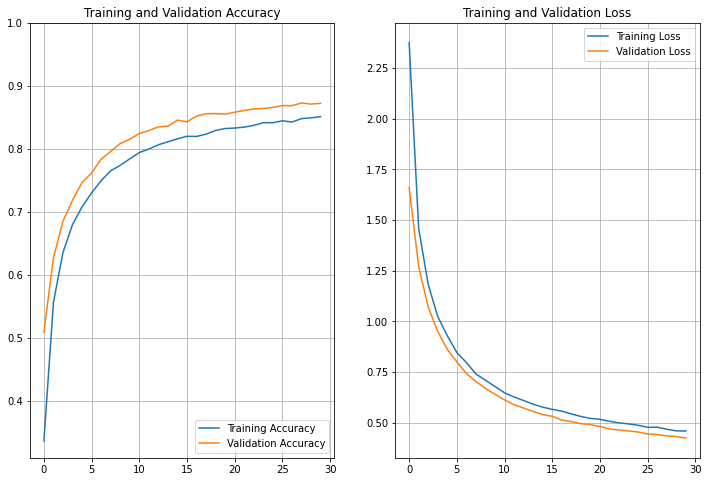

In [ ]:
def plot_history(history, metric, val_metric):
  acc = history.history[metric]
  val_acc = history.history[val_metric]

  loss=history.history['loss']
  val_loss=history.history['val_loss']

  epochs_range = range(len(acc))

  fig=plt.figure(figsize=(12, 8))
  plt.subplot(1, 2, 1)
  plt.plot(epochs_range, acc, label='Training Accuracy')
  plt.plot(epochs_range, val_acc, label='Validation Accuracy')
  plt.legend(loc='lower right')
  plt.ylim([min(plt.ylim()),1])
  plt.grid(True)
  plt.title('Training and Validation Accuracy')

  plt.subplot(1, 2, 2)
  plt.plot(epochs_range, loss, label='Training Loss')
  plt.plot(epochs_range, val_loss, label='Validation Loss')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.title('Training and Validation Loss')
  plt.show()
  fig.savefig('traininghistory.pdf')

plot_history(history, 'accuracy', 'val_accuracy')

##Fine tuning

In [ ]:
base_model.trainable = True
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model.layers))

# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable =  False

Number of layers in the base model:  154


In [ ]:
model.compile(loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.RMSprop(lr=base_learning_rate/10),
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 160, 160, 3)]     0         
_________________________________________________________________
sequential (Sequential)      (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.truediv (TFOpLambda) (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.subtract (TFOpLambda (None, 160, 160, 3)       0         
_________________________________________________________________
mobilenetv2_1.00_160 (Functi (None, 5, 5, 1280)        2257984   
_________________________________________________________________
global_average_pooling2d (Gl (None, 1280)              0         
_________________________________________________________________
dropout (Dropout)            (None, 1280)              0     

In [ ]:
len(model.trainable_variables)

56

In [ ]:
history.epoch[-1]

29

In [ ]:
fine_tune_epochs = 10
initial_epochs = 30
total_epochs =  initial_epochs + fine_tune_epochs

history_fine = model.fit(train_ds,
                         epochs=total_epochs,
                         initial_epoch=history.epoch[-1],
                         validation_data=val_ds)

Epoch 30/40
981/981 [==============================] - 70s 66ms/step - loss: 0.4376 - accuracy: 0.8487 - val_loss: 0.3281 - val_accuracy: 0.8897
Epoch 31/40
981/981 [==============================] - 64s 65ms/step - loss: 0.3122 - accuracy: 0.8933 - val_loss: 0.2629 - val_accuracy: 0.9139
Epoch 32/40
981/981 [==============================] - 64s 65ms/step - loss: 0.2501 - accuracy: 0.9142 - val_loss: 0.2162 - val_accuracy: 0.9315
Epoch 33/40
981/981 [==============================] - 65s 66ms/step - loss: 0.2118 - accuracy: 0.9284 - val_loss: 0.1687 - val_accuracy: 0.9450
Epoch 34/40
981/981 [==============================] - 64s 65ms/step - loss: 0.1905 - accuracy: 0.9351 - val_loss: 0.1555 - val_accuracy: 0.9495
Epoch 35/40
981/981 [==============================] - 65s 66ms/step - loss: 0.1714 - accuracy: 0.9396 - val_loss: 0.2161 - val_accuracy: 0.9332
Epoch 36/40
981/981 [==============================] - 64s 65ms/step - loss: 0.1551 - accuracy: 0.9481 - val_loss: 0.1361 - val_ac

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [ ]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']

loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']

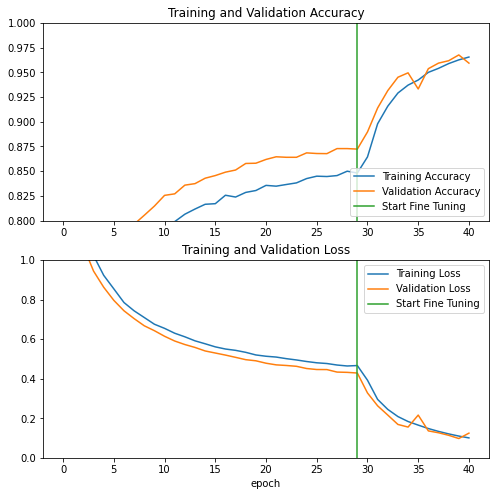

In [ ]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
loss, accuracy = model.evaluate(val_ds)
print('Test accuracy :', accuracy)

246/246 [==============================] - 11s 42ms/step - loss: 0.1247 - accuracy: 0.9593
Test accuracy : 0.9593164324760437


## Save and load the model

In [ ]:
model.save('saved_models/model_finetune/', save_format='tf')


INFO:tensorflow:Assets written to: saved_models/model_finetune/assets


In [ ]:
!pwd

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign


In [ ]:
!ls saved_models/model_finetune/

assets	saved_model.pb	variables


In [ ]:
!zip model_finetune.zip -r saved_models/model_finetune/

  adding: saved_models/model_finetune/ (stored 0%)
  adding: saved_models/model_finetune/variables/ (stored 0%)
  adding: saved_models/model_finetune/variables/variables.index (deflated 77%)
  adding: saved_models/model_finetune/variables/variables.data-00000-of-00001 (deflated 7%)
  adding: saved_models/model_finetune/assets/ (stored 0%)
  adding: saved_models/model_finetune/saved_model.pb (deflated 92%)


In [ ]:
!cp ./model_finetune.zip /content/gdrive/MyDrive/'Colab Notebooks'/Kaggle

In [ ]:
from google.colab import files
files.download('model_finetune.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save('model_finetune.h5')

In [ ]:
# Recreate the exact same model
newsaved_model = tf.keras.models.load_model('saved_models/model_finetune/')

In [ ]:
newsaved_model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 160, 160, 3)]     0         
_________________________________________________________________
sequential (Sequential)      (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.truediv (TFOpLambda) (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.subtract (TFOpLambda (None, 160, 160, 3)       0         
_________________________________________________________________
mobilenetv2_1.00_160 (Functi (None, 5, 5, 1280)        2257984   
_________________________________________________________________
global_average_pooling2d (Gl (None, 1280)              0         
_________________________________________________________________
dropout (Dropout)            (None, 1280)              0     

## Evaluate the model

In [ ]:
#Retrieve a batch of images from the test set
image_batch, label_batch = val_ds.as_numpy_iterator().next()

In [ ]:
label_batch

array([29, 34, 41, 32, 23, 29, 10, 42, 34,  9,  3, 41,  9, 34,  3,  2, 34,
       28, 11, 25,  2, 34,  3, 34,  8, 12, 41,  1,  5,  1, 29, 34],
      dtype=int32)

In [ ]:
predictions = newsaved_model.predict_on_batch(image_batch) #.flatten()
predictions

array([[-27.538647 , -19.5644   , -17.22286  , ..., -31.247295 ,
        -24.498861 , -12.448724 ],
       [ -7.3609467,  -6.827816 , -16.541307 , ..., -14.718191 ,
         -8.143978 ,  -9.678493 ],
       [-13.308262 ,  -5.2227097, -14.611705 , ...,  -2.990856 ,
          6.8962083, -11.1589   ],
       ...,
       [ -9.197577 ,   2.210507 , -22.090143 , ..., -21.228184 ,
        -17.428072 , -18.24594  ],
       [-23.706207 , -17.250109 , -19.169268 , ..., -24.95388  ,
        -23.784258 , -15.440981 ],
       [-10.20395  ,  -5.6916246,  -8.72673  , ...,  -5.404183 ,
         -5.8456054,  -9.520733 ]], dtype=float32)

In [ ]:
predictions = model.predict_on_batch(image_batch) #.flatten()
predictions

array([[-27.538647 , -19.5644   , -17.22286  , ..., -31.247295 ,
        -24.498861 , -12.448724 ],
       [ -7.3609467,  -6.827816 , -16.541307 , ..., -14.718191 ,
         -8.143978 ,  -9.678493 ],
       [-13.308262 ,  -5.2227097, -14.611705 , ...,  -2.990856 ,
          6.8962083, -11.1589   ],
       ...,
       [ -9.197577 ,   2.210507 , -22.090143 , ..., -21.228184 ,
        -17.428072 , -18.24594  ],
       [-23.706207 , -17.250109 , -19.169268 , ..., -24.95388  ,
        -23.784258 , -15.440981 ],
       [-10.20395  ,  -5.6916246,  -8.72673  , ...,  -5.404183 ,
         -5.8456054,  -9.520733 ]], dtype=float32)

In [ ]:
predictions.shape

(32, 43)

In [ ]:
predictions[0].shape

(43,)

In [ ]:
# Apply a softmax since our model returns logits
prediction0 = tf.nn.softmax(predictions[0])
prediction0

<tf.Tensor: shape=(43,), dtype=float32, numpy=
array([1.9868625e-14, 5.7721723e-11, 6.0014604e-10, 1.9998194e-07,
       2.9266875e-13, 2.1015456e-10, 1.1852609e-14, 8.4267052e-14,
       4.3079627e-11, 1.1551834e-11, 7.2453901e-09, 8.8995054e-11,
       2.8008932e-11, 1.7235333e-12, 1.7073863e-12, 9.2570890e-12,
       5.4248983e-10, 1.4152476e-10, 2.4429722e-08, 4.5475863e-13,
       1.9579968e-10, 2.2072788e-14, 1.4246671e-14, 6.2784760e-13,
       1.9886889e-15, 7.9830318e-12, 3.8727334e-11, 6.2595427e-07,
       3.4790793e-07, 9.9998713e-01, 1.3784685e-07, 1.3317755e-07,
       1.1402966e-05, 6.5476375e-09, 2.9145564e-08, 1.7026611e-08,
       1.2417876e-10, 4.3656595e-10, 8.3048034e-17, 1.0806301e-14,
       4.8699238e-16, 4.1526935e-13, 7.1062033e-08], dtype=float32)>

In [ ]:
objid=np.argmax(prediction0, axis=-1)
objid

29

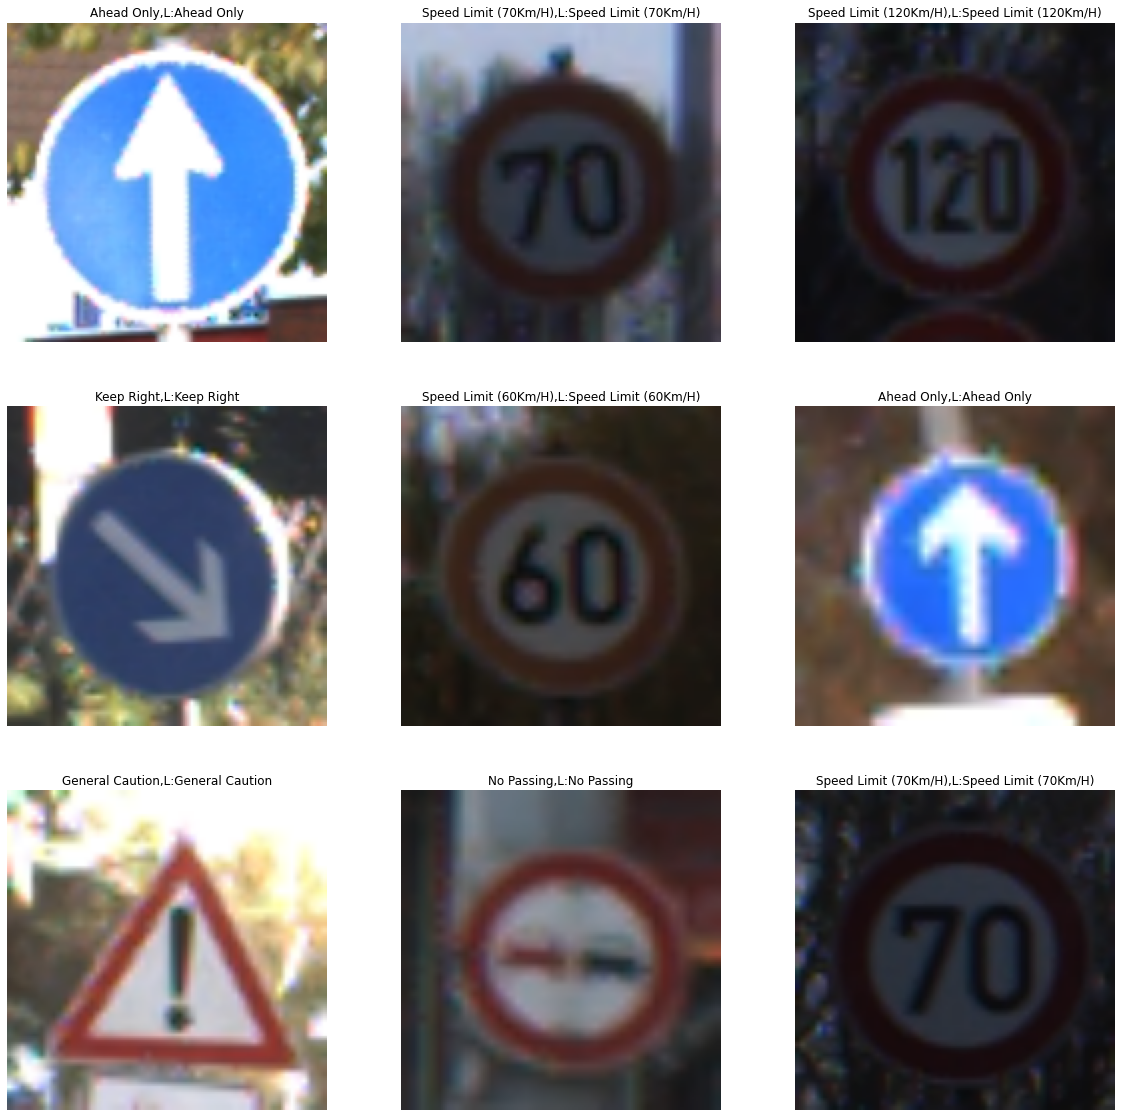

In [ ]:
plt.figure(figsize=(20, 20))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].astype("uint8"))
  prediction_current = tf.nn.softmax(predictions[i])
  objid=np.argmax(prediction_current, axis=-1)
  groundtruth=labels[label_batch[i]]
  plt.title(labels[objid]+',L:'+groundtruth)
  plt.axis("off")

In [ ]:
!pwd

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign


In [ ]:
!wget https://thumbs.dreamstime.com/t/speed-limit-traffic-sign-30-km-h-28093088.jpg -O testspeedlimit30km.jpg

--2021-02-16 21:55:49--  https://thumbs.dreamstime.com/t/speed-limit-traffic-sign-30-km-h-28093088.jpg
Resolving thumbs.dreamstime.com (thumbs.dreamstime.com)... 192.229.163.122
Connecting to thumbs.dreamstime.com (thumbs.dreamstime.com)|192.229.163.122|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12056 (12K) [image/jpeg]
Saving to: ‘testspeedlimit30km.jpg’

testspeedlimit30km. 100%[===================>]  11.77K  --.-KB/s    in 0s      

2021-02-16 21:55:49 (185 MB/s) - ‘testspeedlimit30km.jpg’ saved [12056/12056]



In [ ]:
!ls

gtsrb-german-traffic-sign.zip  model_finetune.zip  testspeedlimit30km.jpg
meta			       saved_models	   train
Meta			       test		   Train
Meta.csv		       Test		   Train.csv
model_finetune.h5	       Test.csv		   traininghistory.pdf


In [ ]:
from numpy import asarray
from PIL import Image
# load image
image_path = 'testspeedlimit30km.jpg'
image = Image.open(image_path)
im_resized = image.resize((img_width, img_height))
pixels = asarray(im_resized)
img_array = tf.expand_dims(pixels, 0) # Create a batch
predictions = newsaved_model.predict(img_array)
prediction_prob=tf.nn.softmax(predictions)
prediction_prob

<tf.Tensor: shape=(1, 43), dtype=float32, numpy=
array([[5.1368200e-08, 6.7353189e-01, 3.8509075e-02, 6.4369491e-03,
        1.5231308e-05, 1.2236483e-02, 5.7530256e-06, 8.4023782e-08,
        2.1192123e-05, 3.1931384e-05, 1.2869771e-04, 1.2678646e-01,
        3.4303408e-02, 8.0553364e-06, 3.4157027e-04, 7.0032757e-04,
        4.7038130e-02, 4.2234869e-06, 2.2115407e-03, 6.2145300e-05,
        2.2761806e-06, 1.9299256e-05, 9.1573975e-06, 6.7804381e-04,
        2.1433813e-02, 1.6640893e-03, 3.2219744e-11, 4.7823796e-03,
        1.5889273e-03, 1.9246495e-06, 7.4608721e-07, 1.0463664e-05,
        4.6490648e-05, 9.4471073e-07, 1.4356110e-05, 1.0828317e-05,
        1.7862104e-09, 2.4820156e-11, 2.1190833e-02, 1.3905289e-09,
        1.1302632e-06, 6.1399597e-03, 3.1111656e-05]], dtype=float32)>

In [ ]:
objid=np.argmax(prediction_prob[0], axis=-1)
labels[objid]

'Speed Limit (30Km/H)'

# Tensorflow Resnet

In [ ]:
import numpy as np
import time

import PIL.Image as Image
import matplotlib.pylab as plt

import tensorflow as tf
import tensorflow_hub as hub

In [ ]:
base_dir = '/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train'
print(base_dir)

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train


In [ ]:
batch_size = 32
img_height = 224 #180
img_width = 224 #180
IMAGE_SIZE = (img_height, img_width)

In [ ]:
labels = ['20 km/h', '30 km/h', '50 km/h', '60 km/h', '70 km/h', '80 km/h', '80 km/h end', '100 km/h', '120 km/h', 'No overtaking',
               'No overtaking for trucks', 'Crossroad with secondary way', 'Main road', 'Give way', 'Stop', 'Road up', 'Road up for truck', 'No entry',
               'Other dangerous', 'Turn left', 'Turn right', 'Winding road', 'Hollow road', 'Slippery road', 'Narrowing road', 'Roadwork', 'Traffic light',
               'Pedestrian', 'Children', 'Bike', 'Snow', 'Deer', 'End of the limits', 'Only right', 'Only left', 'Only straight', 'Only straight and right', 
               'Only straight and left', 'Take right', 'Take left', 'Circle crossroad', 'End of overtaking limit', 'End of overtaking limit for truck']

In [ ]:
#https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 31368 files for training.


In [ ]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  base_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 39209 files belonging to 43 classes.
Using 7841 files for validation.


In [ ]:
class_names = np.array(train_ds.class_names)
print(class_names)

['0' '1' '10' '11' '12' '13' '14' '15' '16' '17' '18' '19' '2' '20' '21'
 '22' '23' '24' '25' '26' '27' '28' '29' '3' '30' '31' '32' '33' '34' '35'
 '36' '37' '38' '39' '4' '40' '41' '42' '5' '6' '7' '8' '9']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 224, 224, 3)
(32,)


In [ ]:
numclasses=len(class_names)
def create_model():
    IMAGE_SIZE = (img_height, img_width)
    IMG_SHAPE = IMAGE_SIZE + (3,)
    pretrained_model = tf.keras.applications.MobileNetV2(input_shape=[*IMAGE_SIZE, 3], include_top=False, weights='imagenet')
    #pretrained_model = tf.keras.applications.MobileNetV2(input_shape=[*IMAGE_SIZE, 3], include_top=False)
    #pretrained_model = tf.keras.applications.Xception(input_shape=[*IMAGE_SIZE, 3], include_top=False)
    #pretrained_model = tf.keras.applications.VGG16(weights='imagenet', include_top=False ,input_shape=[*IMAGE_SIZE, 3])
    #pretrained_model = tf.keras.applications.ResNet50(weights='imagenet', include_top=False, input_shape=[*IMAGE_SIZE, 3])
    #pretrained_model = tf.keras.applications.MobileNet(weights='imagenet', include_top=False, input_shape=[*IMAGE_SIZE, 3])
    # EfficientNet can be loaded through efficientnet.tfkeras library (https://github.com/qubvel/efficientnet)
    #pretrained_model = efficientnet.tfkeras.EfficientNetB0(weights='imagenet', include_top=False)

    #tf.keras.applications.MobileNetV2 for use as your base model, This model expects pixel vaues in [-1,1]
    preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

    data_augmentation = tf.keras.Sequential([
      tf.keras.layers.experimental.preprocessing.RandomFlip('horizontal'),
      tf.keras.layers.experimental.preprocessing.RandomRotation(0.2),
    ])
    
    pretrained_model.trainable = False

    header = tf.keras.Sequential([
        tf.keras.layers.GlobalAveragePooling2D(),
        #tf.keras.layers.Flatten(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(numclasses, activation='softmax', dtype=tf.float32) # the float32 is needed on softmax layer when using mixed precision
    ])

    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = pretrained_model(x, training=False)
    outputs = header(x)
    model = tf.keras.Model(inputs, outputs)

    base_learning_rate = 0.0001
    model.compile(optimizer=tf.keras.optimizers.Adam(lr=base_learning_rate),
              #loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

    return model

In [ ]:
model3 = create_model()
model3.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_10 (InputLayer)        [(None, 160, 160, 3)]     0         
_________________________________________________________________
sequential_11 (Sequential)   (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.truediv_2 (TFOpLambd (None, 160, 160, 3)       0         
_________________________________________________________________
tf.math.subtract_2 (TFOpLamb (None, 160, 160, 3)       0         
_________________________________________________________________
mobilenetv2_1.00_160 (Functi (None, 5, 5, 1280)        2257984   
_________________________________________________________________
sequential_12 (Sequential)   (None, 43)                55083     
Total params: 2,313,067
Trainable params: 55,083
Non-trainable params: 2,257,984
____________________________________________

In [ ]:
import time
start_time = time.time()
EPOCHS=30
history = model3.fit(train_ds, validation_data=val_ds,epochs=EPOCHS)

final_accuracy = history.history["val_accuracy"][-5:]
print("FINAL ACCURACY MEAN-5: ", np.mean(final_accuracy))
print("TRAINING TIME: ", time.time() - start_time, " sec")

Epoch 1/30
981/981 [==============================] - 37s 36ms/step - loss: 3.0085 - accuracy: 0.2147 - val_loss: 1.6593 - val_accuracy: 0.5172
Epoch 2/30
981/981 [==============================] - 26s 27ms/step - loss: 1.5471 - accuracy: 0.5302 - val_loss: 1.2721 - val_accuracy: 0.6256
Epoch 3/30
981/981 [==============================] - 26s 26ms/step - loss: 1.2268 - accuracy: 0.6191 - val_loss: 1.0725 - val_accuracy: 0.6842
Epoch 4/30
981/981 [==============================] - 26s 26ms/step - loss: 1.0535 - accuracy: 0.6727 - val_loss: 0.9483 - val_accuracy: 0.7201
Epoch 5/30
981/981 [==============================] - 26s 26ms/step - loss: 0.9490 - accuracy: 0.7005 - val_loss: 0.8620 - val_accuracy: 0.7430
Epoch 6/30
981/981 [==============================] - 26s 26ms/step - loss: 0.8656 - accuracy: 0.7259 - val_loss: 0.7939 - val_accuracy: 0.7653
Epoch 7/30
981/981 [==============================] - 26s 26ms/step - loss: 0.8116 - accuracy: 0.7455 - val_loss: 0.7429 - val_accuracy:

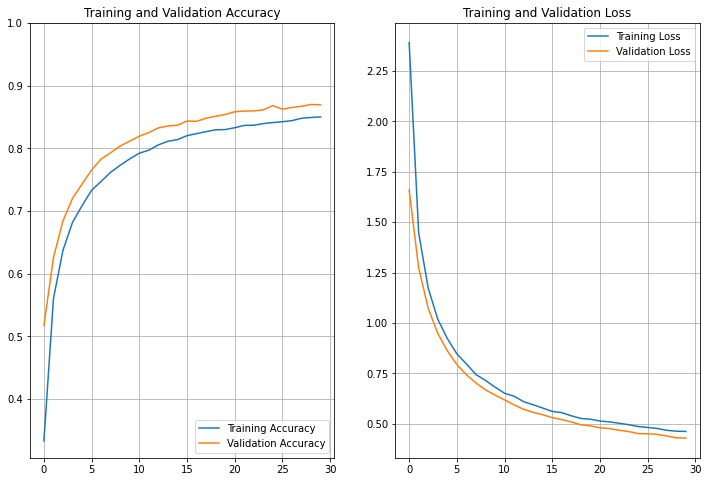

In [ ]:
def plot_history(history, metric, val_metric):
  acc = history.history[metric]
  val_acc = history.history[val_metric]

  loss=history.history['loss']
  val_loss=history.history['val_loss']

  epochs_range = range(len(acc))

  fig=plt.figure(figsize=(12, 8))
  plt.subplot(1, 2, 1)
  plt.plot(epochs_range, acc, label='Training Accuracy')
  plt.plot(epochs_range, val_acc, label='Validation Accuracy')
  plt.legend(loc='lower right')
  plt.ylim([min(plt.ylim()),1])
  plt.grid(True)
  plt.title('Training and Validation Accuracy')

  plt.subplot(1, 2, 2)
  plt.plot(epochs_range, loss, label='Training Loss')
  plt.plot(epochs_range, val_loss, label='Validation Loss')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.title('Training and Validation Loss')
  plt.show()
  fig.savefig('traininghistory.pdf')

plot_history(history, 'accuracy', 'val_accuracy')

## ResNet Model

In [ ]:
numclasses=len(class_names)
def create_model2():
    IMAGE_SIZE = (img_height, img_width)
    IMG_SHAPE = IMAGE_SIZE + (3,)
    #pretrained_model = tf.keras.applications.MobileNetV2(input_shape=[*IMAGE_SIZE, 3], include_top=False, weights='imagenet')
    #pretrained_model = tf.keras.applications.MobileNetV2(input_shape=[*IMAGE_SIZE, 3], include_top=False)
    #pretrained_model = tf.keras.applications.Xception(input_shape=[*IMAGE_SIZE, 3], include_top=False)
    #pretrained_model = tf.keras.applications.VGG16(weights='imagenet', include_top=False ,input_shape=[*IMAGE_SIZE, 3])
    pretrained_model = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=[*IMAGE_SIZE, 3]) #https://www.tensorflow.org/api_docs/python/tf/keras/applications/ResNet50V2
    #pretrained_model = tf.keras.applications.MobileNet(weights='imagenet', include_top=False, input_shape=[*IMAGE_SIZE, 3])
    # EfficientNet can be loaded through efficientnet.tfkeras library (https://github.com/qubvel/efficientnet)
    #pretrained_model = efficientnet.tfkeras.EfficientNetB0(weights='imagenet', include_top=False)

    #tf.keras.applications.MobileNetV2 for use as your base model, This model expects pixel vaues in [-1,1]
    #preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
    #preprocess_input = tf.keras.applications.ResNet50V2.preprocess_input
    preprocess_input = tf.keras.Sequential([
      tf.keras.layers.experimental.preprocessing.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
      #tf.keras.applications.ResNet50V2.preprocess_input,
    ])

    data_augmentation = tf.keras.Sequential([
      tf.keras.layers.experimental.preprocessing.RandomFlip('horizontal'),
      tf.keras.layers.experimental.preprocessing.RandomRotation(0.2),
    ])
    
    pretrained_model.trainable = False

    header = tf.keras.Sequential([
        tf.keras.layers.GlobalAveragePooling2D(),
        #tf.keras.layers.Flatten(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(numclasses, activation='softmax', dtype=tf.float32) # the float32 is needed on softmax layer when using mixed precision
    ])

    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = pretrained_model(x, training=False)
    outputs = header(x)
    model = tf.keras.Model(inputs, outputs)

    base_learning_rate = 0.0001
    model.compile(optimizer=tf.keras.optimizers.Adam(lr=base_learning_rate),
              #loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

    return model

In [ ]:
model4 = create_model2()
model4.summary()

94674944/94668760 [==============================] - 1s 0us/step
Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
sequential_1 (Sequential)    (None, 224, 224, 3)       0         
_________________________________________________________________
sequential (Sequential)      (None, 224, 224, 3)       0         
_________________________________________________________________
resnet50v2 (Functional)      (None, 7, 7, 2048)        23564800  
_________________________________________________________________
sequential_2 (Sequential)    (None, 43)                88107     
Total params: 23,652,907
Trainable params: 88,107
Non-trainable params: 23,564,800
_________________________________________________________________


In [ ]:
import time
start_time = time.time()
EPOCHS=30
history4 = model4.fit(train_ds, validation_data=val_ds,epochs=EPOCHS)

final_accuracy = history4.history["val_accuracy"][-5:]
print("FINAL ACCURACY MEAN-5: ", np.mean(final_accuracy))
print("TRAINING TIME: ", time.time() - start_time, " sec")

Epoch 1/30
981/981 [==============================] - 65s 60ms/step - loss: 2.8768 - accuracy: 0.2361 - val_loss: 1.6736 - val_accuracy: 0.5189
Epoch 2/30
981/981 [==============================] - 50s 51ms/step - loss: 1.4228 - accuracy: 0.5820 - val_loss: 1.2752 - val_accuracy: 0.6382
Epoch 3/30
981/981 [==============================] - 49s 50ms/step - loss: 1.1155 - accuracy: 0.6626 - val_loss: 1.0813 - val_accuracy: 0.6975
Epoch 4/30
981/981 [==============================] - 50s 51ms/step - loss: 0.9599 - accuracy: 0.7108 - val_loss: 0.9655 - val_accuracy: 0.7254
Epoch 5/30
981/981 [==============================] - 50s 51ms/step - loss: 0.8573 - accuracy: 0.7405 - val_loss: 0.8784 - val_accuracy: 0.7532
Epoch 6/30
981/981 [==============================] - 50s 51ms/step - loss: 0.7807 - accuracy: 0.7647 - val_loss: 0.8131 - val_accuracy: 0.7721
Epoch 7/30
981/981 [==============================] - 50s 51ms/step - loss: 0.7284 - accuracy: 0.7766 - val_loss: 0.7652 - val_accuracy:

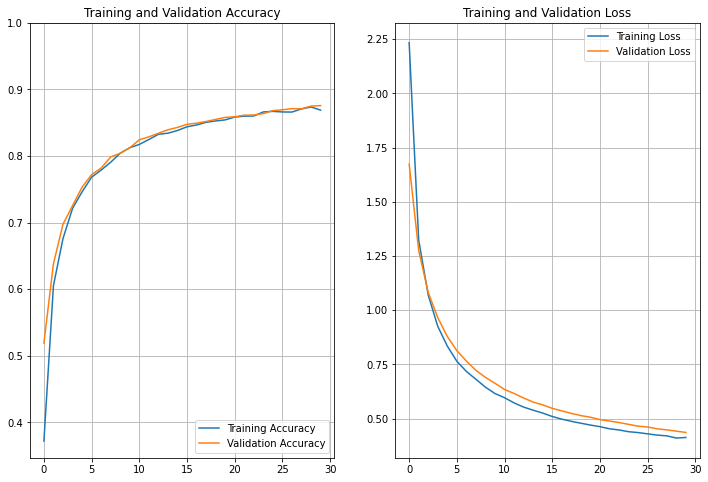

In [ ]:
def plot_history(history, metric, val_metric):
  acc = history.history[metric]
  val_acc = history.history[val_metric]

  loss=history.history['loss']
  val_loss=history.history['val_loss']

  epochs_range = range(len(acc))

  fig=plt.figure(figsize=(12, 8))
  plt.subplot(1, 2, 1)
  plt.plot(epochs_range, acc, label='Training Accuracy')
  plt.plot(epochs_range, val_acc, label='Validation Accuracy')
  plt.legend(loc='lower right')
  plt.ylim([min(plt.ylim()),1])
  plt.grid(True)
  plt.title('Training and Validation Accuracy')

  plt.subplot(1, 2, 2)
  plt.plot(epochs_range, loss, label='Training Loss')
  plt.plot(epochs_range, val_loss, label='Validation Loss')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.title('Training and Validation Loss')
  plt.show()
  fig.savefig('traininghistory.pdf')

plot_history(history4, 'accuracy', 'val_accuracy')

## Finetune ResNet

In [ ]:
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(model4.layers))

Number of layers in the base model:  5


In [ ]:
model4.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
sequential_1 (Sequential)    (None, 224, 224, 3)       0         
_________________________________________________________________
sequential (Sequential)      (None, 224, 224, 3)       0         
_________________________________________________________________
resnet50v2 (Functional)      (None, 7, 7, 2048)        23564800  
_________________________________________________________________
sequential_2 (Sequential)    (None, 43)                88107     
Total params: 23,652,907
Trainable params: 88,107
Non-trainable params: 23,564,800
_________________________________________________________________


In [ ]:
model4_base=model4.layers[3]

In [ ]:
print("Number of layers in the base model: ", len(model4_base.layers)) 

Number of layers in the base model:  190


In [ ]:
for layer in model4_base.layers:
  print(layer.trainable)

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [ ]:
# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the `fine_tune_at` layer, fine tune layers after
for layer in model4.layers[3].layers[fine_tune_at:]:
  layer.trainable =  True #False

In [ ]:
for layer in model4.layers[3].layers:
  print(layer.trainable)

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


In [ ]:
model4.layers[3].trainable = True

In [ ]:
model4.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
sequential_1 (Sequential)    (None, 224, 224, 3)       0         
_________________________________________________________________
sequential (Sequential)      (None, 224, 224, 3)       0         
_________________________________________________________________
resnet50v2 (Functional)      (None, 7, 7, 2048)        23564800  
_________________________________________________________________
sequential_2 (Sequential)    (None, 43)                88107     
Total params: 23,652,907
Trainable params: 23,607,467
Non-trainable params: 45,440
_________________________________________________________________


In [ ]:
base_learning_rate = 0.0001
model4.compile(optimizer=tf.keras.optimizers.Adam(lr=base_learning_rate/10),
          #loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
          loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
          metrics=['accuracy'])

In [ ]:
model4.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
sequential_1 (Sequential)    (None, 224, 224, 3)       0         
_________________________________________________________________
sequential (Sequential)      (None, 224, 224, 3)       0         
_________________________________________________________________
resnet50v2 (Functional)      (None, 7, 7, 2048)        23564800  
_________________________________________________________________
sequential_2 (Sequential)    (None, 43)                88107     
Total params: 23,652,907
Trainable params: 23,607,467
Non-trainable params: 45,440
_________________________________________________________________


In [ ]:
len(model4.trainable_variables)

174

In [ ]:
history4.epoch[-1]

29

In [ ]:
fine_tune_epochs = 10
initial_epochs = 30
total_epochs =  initial_epochs + fine_tune_epochs

history4_fine = model4.fit(train_ds,
                         epochs=total_epochs,
                         initial_epoch=history4.epoch[-1],
                         validation_data=val_ds)

Epoch 30/40
981/981 [==============================] - 121s 119ms/step - loss: 0.2781 - accuracy: 0.9045 - val_loss: 0.0959 - val_accuracy: 0.9668
Epoch 31/40
981/981 [==============================] - 116s 118ms/step - loss: 0.1082 - accuracy: 0.9617 - val_loss: 0.0746 - val_accuracy: 0.9733
Epoch 32/40
981/981 [==============================] - 116s 118ms/step - loss: 0.0687 - accuracy: 0.9768 - val_loss: 0.0838 - val_accuracy: 0.9689
Epoch 33/40
981/981 [==============================] - 116s 118ms/step - loss: 0.0579 - accuracy: 0.9804 - val_loss: 0.0321 - val_accuracy: 0.9879
Epoch 34/40
981/981 [==============================] - 116s 118ms/step - loss: 0.0378 - accuracy: 0.9875 - val_loss: 0.0391 - val_accuracy: 0.9865
Epoch 35/40
981/981 [==============================] - 116s 118ms/step - loss: 0.0357 - accuracy: 0.9869 - val_loss: 0.0357 - val_accuracy: 0.9881
Epoch 36/40
981/981 [==============================] - 116s 118ms/step - loss: 0.0265 - accuracy: 0.9907 - val_loss: 0

In [ ]:
acc = history4.history['accuracy']
val_acc = history4.history['val_accuracy']

loss = history4.history['loss']
val_loss = history4.history['val_loss']

In [ ]:
acc += history4_fine.history['accuracy']
val_acc += history4_fine.history['val_accuracy']

loss += history4_fine.history['loss']
val_loss += history4_fine.history['val_loss']

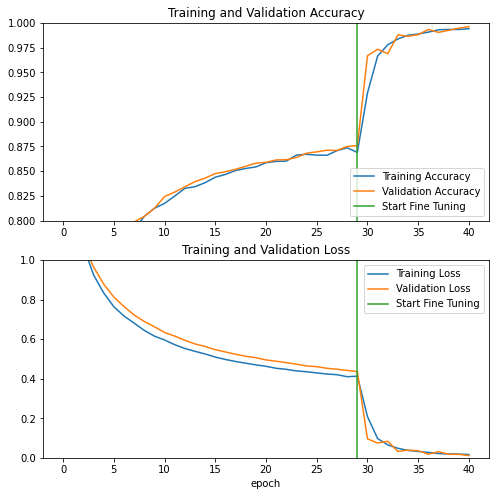

In [ ]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
loss, accuracy = model4.evaluate(val_ds)
print('Test accuracy :', accuracy)

246/246 [==============================] - 16s 65ms/step - loss: 0.0115 - accuracy: 0.9962
Test accuracy : 0.9961739778518677


In [ ]:
model4.save('saved_models/resnet50model_finetune/', save_format='tf')

INFO:tensorflow:Assets written to: saved_models/resnet50model_finetune/assets


In [ ]:
!ls

gtsrb-german-traffic-sign.zip  Meta.csv      Test      Train
meta			       saved_models  Test.csv  Train.csv
Meta			       test	     train     traininghistory.pdf


In [ ]:
!zip resnet50model_finetune.zip -r ./saved_models

  adding: saved_models/ (stored 0%)
  adding: saved_models/resnet50model_finetune/ (stored 0%)
  adding: saved_models/resnet50model_finetune/variables/ (stored 0%)
  adding: saved_models/resnet50model_finetune/variables/variables.data-00000-of-00001 (deflated 7%)
  adding: saved_models/resnet50model_finetune/variables/variables.index (deflated 80%)
  adding: saved_models/resnet50model_finetune/saved_model.pb (deflated 93%)
  adding: saved_models/resnet50model_finetune/assets/ (stored 0%)


In [ ]:
from google.colab import files
files.download('resnet50model_finetune.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Evaluate

In [ ]:
#Retrieve a batch of images from the test set
image_batch, label_batch = val_ds.as_numpy_iterator().next()

In [ ]:
predicted_batch = model4.predict(image_batch)
predicted_batch

array([[9.97264100e-17, 4.91733034e-15, 3.31343852e-15, ...,
        1.30889764e-20, 4.86355151e-13, 7.60824373e-14],
       [3.25026685e-16, 6.67909006e-10, 4.29520447e-10, ...,
        2.64108107e-21, 4.85966836e-16, 9.37579766e-13],
       [9.15642538e-20, 5.42133537e-22, 7.36318627e-18, ...,
        1.99491525e-22, 1.35399101e-19, 1.12606434e-15],
       ...,
       [2.36718067e-12, 4.10380985e-13, 4.30961820e-12, ...,
        1.27608378e-18, 5.45140715e-14, 3.50694273e-13],
       [9.00909194e-23, 1.47200681e-16, 6.29000248e-17, ...,
        6.15737536e-21, 2.66955059e-16, 3.15464398e-16],
       [1.00170744e-21, 1.88626411e-14, 5.64097103e-16, ...,
        1.67128069e-18, 2.60059562e-14, 1.87306361e-14]], dtype=float32)

In [ ]:
predicted_id = np.argmax(predicted_batch, axis=-1)
predicted_id

array([32, 39, 10,  2, 29, 29, 25,  2,  5,  9, 22, 32, 32, 29, 34, 24, 12,
        9, 25,  1, 12, 42,  6, 40, 16, 32,  9, 38,  4, 19,  9,  9])

In [ ]:
predicted_label_batch = labels[predicted_id[0]]
predicted_label_batch

'End of the limits'

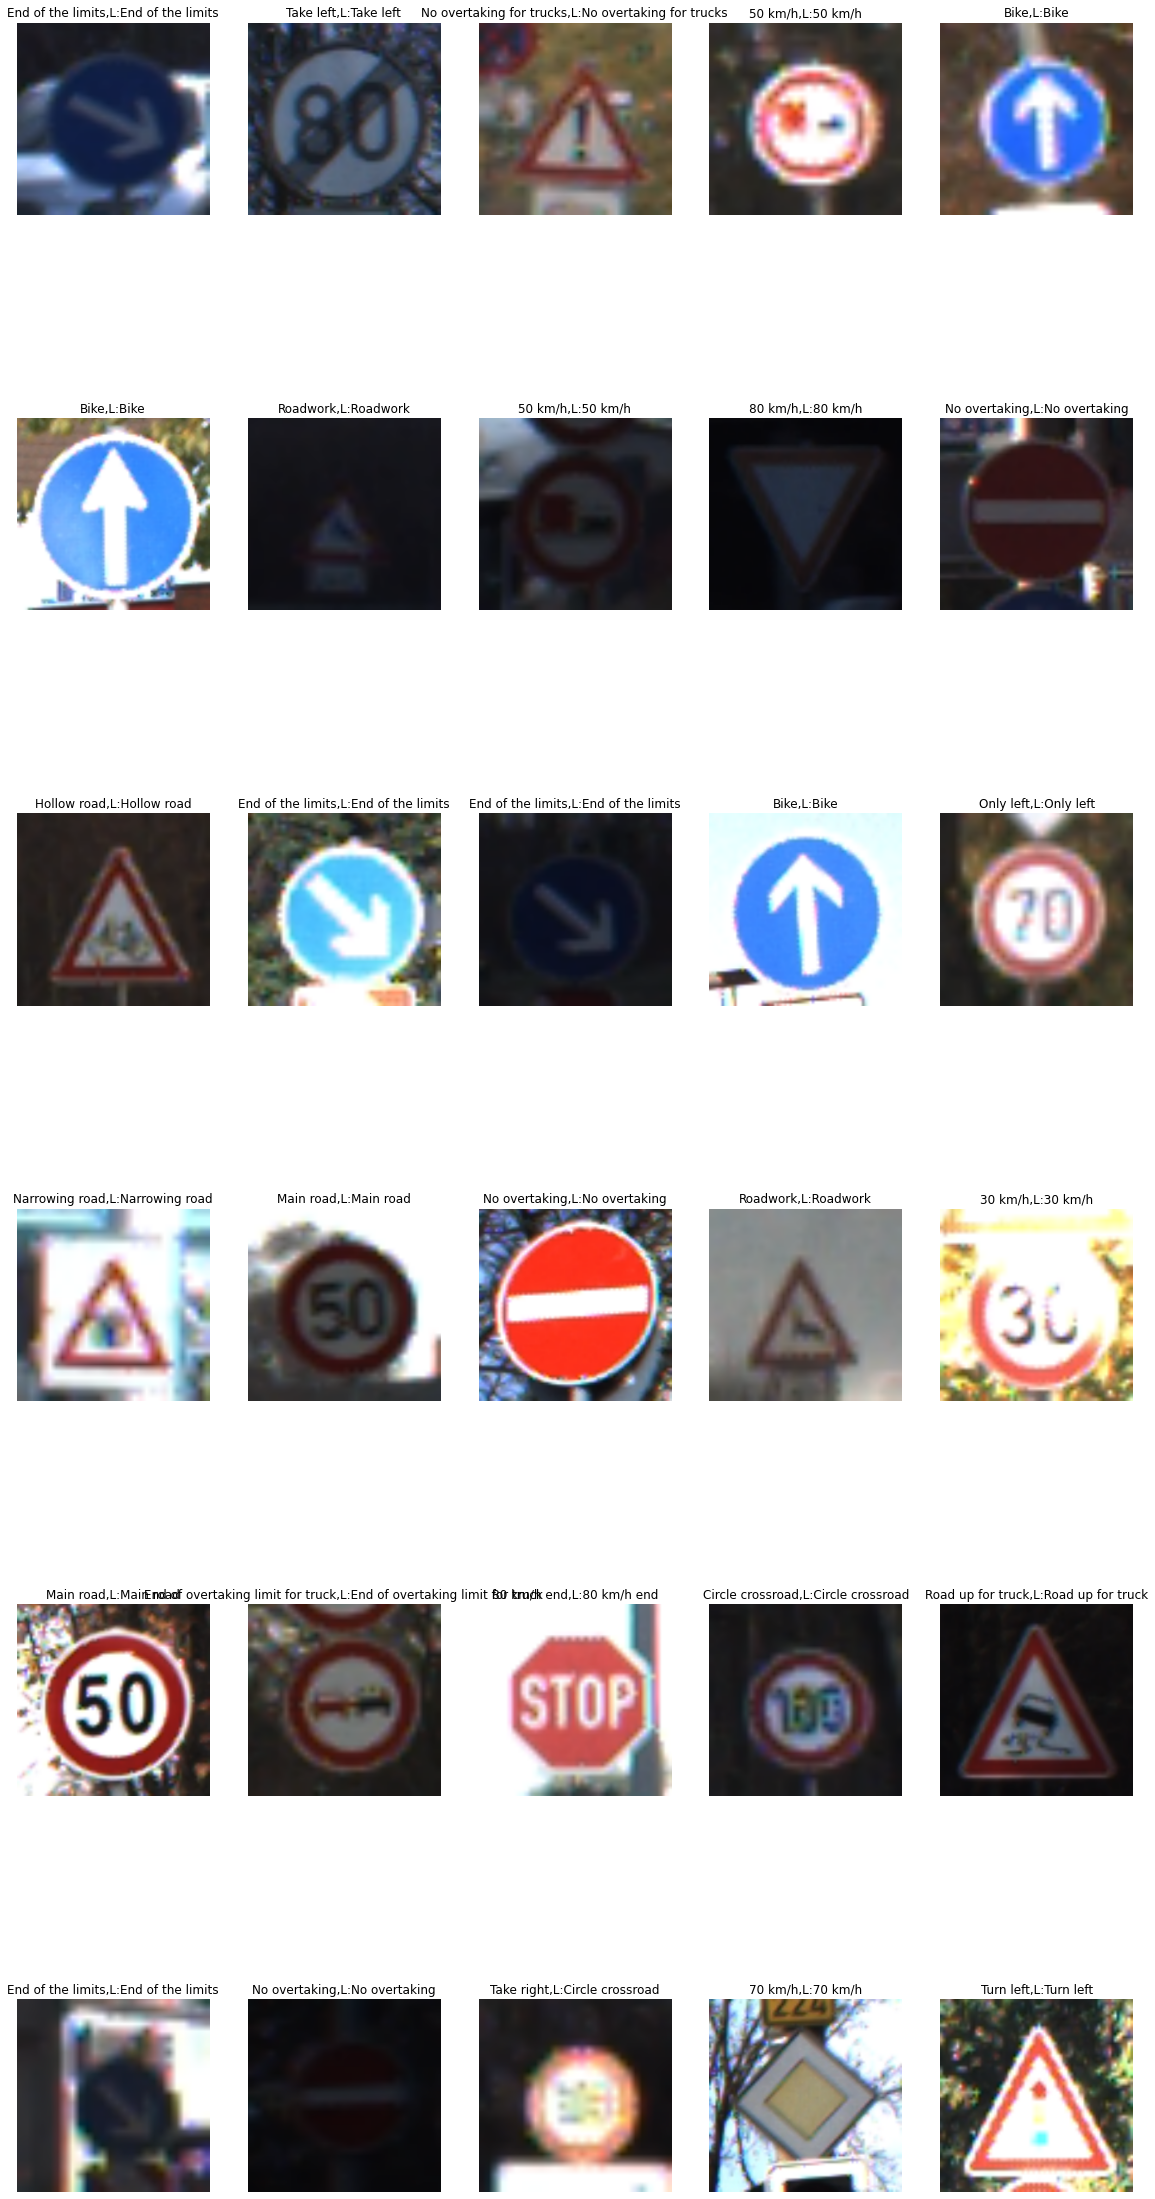

In [ ]:
plt.figure(figsize=(20, 40))
plt.subplots_adjust(hspace=1)
for i in range(30):
  plt.subplot(6,5,i+1)
  plt.imshow(image_batch[i].astype("uint8"))
  prediction_current = tf.nn.softmax(predicted_batch[i])
  objid=np.argmax(prediction_current, axis=-1)
  groundtruth=labels[label_batch[i]]
  plt.title(labels[objid]+',L:'+groundtruth)
  plt.axis("off")

In [ ]:
!ls

gtsrb-german-traffic-sign.zip  saved_models	       train
meta			       test		       Train
Meta			       Test		       Train.csv
Meta.csv		       Test.csv		       traininghistory.pdf
resnet50model_finetune.zip     testspeedlimit30km.jpg


In [ ]:
test_df = pd.read_csv('Test.csv')
# display a sneak peek of the data
test_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


In [ ]:
test_df.tail()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
12625,42,41,5,6,37,36,12,Test/12625.png
12626,50,51,6,5,45,46,33,Test/12626.png
12627,29,29,6,6,24,24,6,Test/12627.png
12628,48,49,5,6,43,44,7,Test/12628.png
12629,32,31,6,5,27,26,10,Test/12629.png


In [ ]:
labels[1]

'30 km/h'

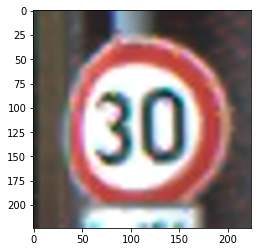

In [ ]:
from matplotlib import pyplot as plt
from PIL import Image
image_path="Test/00001.png"
image = Image.open(image_path).resize((img_width, img_height))
plt.imshow(image)

In [ ]:
image = np.array(image)
#image = np.array(image)/255.0
result = model4.predict(image[np.newaxis, ...])
result.shape

(1, 43)

In [ ]:
np.argmax(result[0], axis=-1)

1

In [ ]:
labels[np.argmax(result[0], axis=-1)]

'30 km/h'

In [ ]:
!wget https://media.galwaydaily.com/wp-content/uploads/2020/06/24084000/Luxembourg_road_sign_C14_30_kmh.jpg -O testspeedlimit30km.jpg

--2021-02-22 05:08:00--  https://media.galwaydaily.com/wp-content/uploads/2020/06/24084000/Luxembourg_road_sign_C14_30_kmh.jpg
Resolving media.galwaydaily.com (media.galwaydaily.com)... 143.204.209.53, 143.204.209.97, 143.204.209.73, ...
Connecting to media.galwaydaily.com (media.galwaydaily.com)|143.204.209.53|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 436487 (426K) [image/jpeg]
Saving to: ‘testspeedlimit30km.jpg’

testspeedlimit30km. 100%[===================>] 426.26K  --.-KB/s    in 0.1s    

2021-02-22 05:08:01 (3.79 MB/s) - ‘testspeedlimit30km.jpg’ saved [436487/436487]



In [ ]:
!ls

gtsrb-german-traffic-sign.zip  saved_models	       train
meta			       speedlimit30km.jpg      Train
Meta			       test		       Train.csv
Meta.csv		       Test		       traininghistory.pdf
resnet50model_finetune.zip     Test.csv
RUS_044.jpg		       testspeedlimit30km.jpg


In [ ]:
img_width

224

In [ ]:
img_height

224

In [ ]:
!pwd

/content/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign


In [ ]:
from numpy import asarray
from PIL import Image
# load image
image_path = 'testspeedlimit30km.jpg'#'/content/road_sign_C14_30_kmh.jpg'
image = Image.open(image_path).resize((img_width, img_height))
#image = np.array(image)/255.0

In [ ]:
image = np.array(image)
image[np.newaxis, ...].shape

(1, 224, 224, 3)

In [ ]:
result = model4.predict(image[np.newaxis, ...])
result.shape

(1, 43)

In [ ]:
result

array([[4.48121876e-03, 9.36675668e-01, 1.41396339e-09, 1.43851386e-09,
        1.56011133e-08, 1.06537876e-10, 4.98672037e-09, 1.57593434e-13,
        7.68971642e-09, 3.16877991e-12, 9.06387118e-11, 1.59588665e-09,
        5.87556958e-02, 4.99102870e-10, 7.64480959e-08, 3.71925893e-11,
        3.82349839e-07, 1.24365422e-11, 7.45551287e-10, 1.47117073e-12,
        9.06826350e-11, 1.84817459e-08, 6.32999729e-13, 2.38700686e-05,
        1.53880570e-13, 7.32257516e-13, 1.01841617e-13, 5.50941513e-05,
        5.99442540e-09, 1.29768774e-11, 8.67134542e-09, 1.85509483e-10,
        1.73259110e-07, 3.77785977e-06, 1.20448408e-06, 1.11761756e-06,
        1.10237952e-08, 9.32413036e-10, 4.58413069e-07, 6.77234727e-11,
        1.08873492e-11, 8.30764957e-10, 1.14461011e-06]], dtype=float32)

In [ ]:
np.argmax(result[0], axis=-1)

1

In [ ]:
labels[np.argmax(result[0], axis=-1)]

'30 km/h'

## TF Lite
ref: https://www.tensorflow.org/lite/guide/get_started
https://www.tensorflow.org/lite/guide/inference#load_and_run_a_model_in_python

In [ ]:
import tensorflow as tf
saved_model_dir = 'saved_models/resnet50model_finetune/'
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
tflite_model = converter.convert()
open("converted_model.tflite", "wb").write(tflite_model)

94432008

In [ ]:
!ls

converted_model.tflite	       RUS_044.jpg	   testspeedlimit30km.jpg
gtsrb-german-traffic-sign.zip  saved_models	   train
meta			       speedlimit30km.jpg  Train
Meta			       test		   Train.csv
Meta.csv		       Test		   traininghistory.pdf
resnet50model_finetune.zip     Test.csv


In [ ]:
# Load the TFLite model and allocate tensors.
interpreter = tf.lite.Interpreter(model_path="converted_model.tflite")
interpreter.allocate_tensors()

# Get input and output tensors.
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Test the model on random input data.
input_shape = input_details[0]['shape']
input_shape

array([  1, 224, 224,   3], dtype=int32)

In [ ]:
input_details

[{'dtype': numpy.float32,
  'index': 0,
  'name': 'serving_default_input_2:0',
  'quantization': (0.0, 0),
  'quantization_parameters': {'quantized_dimension': 0,
   'scales': array([], dtype=float32),
   'zero_points': array([], dtype=int32)},
  'shape': array([  1, 224, 224,   3], dtype=int32),
  'shape_signature': array([ -1, 224, 224,   3], dtype=int32),
  'sparsity_parameters': {}}]

In [ ]:
output_details

[{'dtype': numpy.float32,
  'index': 275,
  'name': 'StatefulPartitionedCall:0',
  'quantization': (0.0, 0),
  'quantization_parameters': {'quantized_dimension': 0,
   'scales': array([], dtype=float32),
   'zero_points': array([], dtype=int32)},
  'shape': array([ 1, 43], dtype=int32),
  'shape_signature': array([-1, 43], dtype=int32),
  'sparsity_parameters': {}}]

In [ ]:
from numpy import asarray
from PIL import Image
# load image
image_path = 'testspeedlimit30km.jpg'#'/content/road_sign_C14_30_kmh.jpg'
image = Image.open(image_path).resize((img_width, img_height))
image = np.array(image)
input=image[np.newaxis, ...]

In [ ]:
input.shape

(1, 224, 224, 3)

In [ ]:
input_data = np.array(np.random.random_sample(input_shape), dtype=np.float32)

In [ ]:
input_data.shape

(1, 224, 224, 3)

In [ ]:
input_data = np.array(input, dtype=np.float32)
interpreter.set_tensor(input_details[0]['index'], input_data)

interpreter.invoke()

# The function `get_tensor()` returns a copy of the tensor data.
# Use `tensor()` in order to get a pointer to the tensor.
output_data = interpreter.get_tensor(output_details[0]['index'])
print(output_data)

[[4.48122248e-03 9.36675489e-01 1.41397938e-09 1.43852730e-09
  1.56012021e-08 1.06538674e-10 4.98676700e-09 1.57595535e-13
  7.68972974e-09 3.16878576e-12 9.06395584e-11 1.59588021e-09
  5.87560199e-02 4.99102759e-10 7.64483730e-08 3.71928668e-11
  3.82352340e-07 1.24366828e-11 7.45561168e-10 1.47119014e-12
  9.06831416e-11 1.84819218e-08 6.33002060e-13 2.38702250e-05
  1.53882603e-13 7.32261691e-13 1.01843359e-13 5.50940895e-05
  5.99441297e-09 1.29770743e-11 8.67142713e-09 1.85511939e-10
  1.73260901e-07 3.77787387e-06 1.20449056e-06 1.11762699e-06
  1.10238147e-08 9.32418254e-10 4.58415172e-07 6.77242359e-11
  1.08873891e-11 8.30772728e-10 1.14462296e-06]]


In [ ]:
labels[np.argmax(output_data[0], axis=-1)]

'30 km/h'

## Post-training integer quantization

In [ ]:
for image_batch, label_batch in val_ds.take(100):
  pass

image_batch.shape

TensorShape([32, 224, 224, 3])

In [ ]:
def representative_data_gen():
  for input_value, _ in val_ds.take(100):
    yield [input_value]

Post-training quantization

The simplest form of post-training quantization quantizes weights from floating point to 8-bits of precision. This technique is enabled as an option in the TensorFlow Lite converter. At inference, weights are converted from 8-bits of precision to floating point and computed using floating-point kernels. This conversion is done once and cached to reduce latency.

To further improve latency, hybrid operators dynamically quantize activations to 8-bits and perform computations with 8-bit weights and activations. This optimization provides latencies close to fully fixed-point inference. However, the outputs are still stored using floating point, so that the speedup with hybrid ops is less than a full fixed-point computation.

In [ ]:
saved_model_dir = 'saved_models/resnet50model_finetune/'
converter_int8 = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]

In [ ]:
converter_int8.representative_dataset = representative_data_gen

In [ ]:
#To require the converter to only output integer operations, one can specify:
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

In [ ]:
tflite_model = converter.convert()
tflite_model_file = 'converted_model_quant.tflite'

with open(tflite_model_file, "wb") as f:
  f.write(tflite_model)

In [ ]:
!ls

converted_model_quant.tflite   speedlimit30km.jpg
converted_model.tflite	       test
gtsrb-german-traffic-sign.zip  Test
meta			       Test.csv
Meta			       testspeedlimit30km.jpg
Meta.csv		       train
resnet50model_finetune.zip     Train
RUS_044.jpg		       Train.csv
saved_models		       traininghistory.pdf


In [ ]:
try:
  from google.colab import files
  files.download('converted_model_quant.tflite')
except:
  pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Load the TFLite model and allocate tensors.
interpreter_quant = tf.lite.Interpreter(model_path="converted_model_quant.tflite")
interpreter_quant.allocate_tensors()

# Get input and output tensors.
input_details = interpreter_quant.get_input_details()
output_details = interpreter_quant.get_output_details()

# Test the model on random input data.
input_shape = input_details[0]['shape']
input_shape

array([  1, 224, 224,   3], dtype=int32)

In [ ]:
from numpy import asarray
from PIL import Image
# load image
image_path = 'testspeedlimit30km.jpg'#'/content/road_sign_C14_30_kmh.jpg'
image = Image.open(image_path).resize((img_width, img_height))
image = np.array(image)
input=image[np.newaxis, ...]
#image = tf.cast(input, tf.float32)

In [ ]:
input_details

[{'dtype': numpy.float32,
  'index': 0,
  'name': 'serving_default_input_2:0',
  'quantization': (0.0, 0),
  'quantization_parameters': {'quantized_dimension': 0,
   'scales': array([], dtype=float32),
   'zero_points': array([], dtype=int32)},
  'shape': array([  1, 224, 224,   3], dtype=int32),
  'shape_signature': array([ -1, 224, 224,   3], dtype=int32),
  'sparsity_parameters': {}}]

In [ ]:
input_data = np.array(input, dtype=np.float32)
interpreter_quant.set_tensor(input_details[0]['index'], input_data)

interpreter_quant.invoke()

# The function `get_tensor()` returns a copy of the tensor data.
# Use `tensor()` in order to get a pointer to the tensor.
output_data = interpreter_quant.get_tensor(output_details[0]['index'])
print(output_data)

[[4.48122248e-03 9.36675489e-01 1.41397938e-09 1.43852730e-09
  1.56012021e-08 1.06538674e-10 4.98676700e-09 1.57595535e-13
  7.68972974e-09 3.16878576e-12 9.06395584e-11 1.59588021e-09
  5.87560199e-02 4.99102759e-10 7.64483730e-08 3.71928668e-11
  3.82352340e-07 1.24366828e-11 7.45561168e-10 1.47119014e-12
  9.06831416e-11 1.84819218e-08 6.33002060e-13 2.38702250e-05
  1.53882603e-13 7.32261691e-13 1.01843359e-13 5.50940895e-05
  5.99441297e-09 1.29770743e-11 8.67142713e-09 1.85511939e-10
  1.73260901e-07 3.77787387e-06 1.20449056e-06 1.11762699e-06
  1.10238147e-08 9.32418254e-10 4.58415172e-07 6.77242359e-11
  1.08873891e-11 8.30772728e-10 1.14462296e-06]]


In [ ]:
labels[np.argmax(output_data[0], axis=-1)]

'30 km/h'

## TF Coreml
ref: https://coremltools.readme.io/docs/introductory-quickstart

In [ ]:
!pip install --upgrade coremltools
!pip install -U tfcoreml

     |████████████████████████████████| 3.4MB 12.7MB/s 
  Created wheel for attr: filename=attr-0.3.1-cp36-none-any.whl size=2459 sha256=f62f6e8942af49320d4cad90af2faee7e04610dfeb8747ee210e5bedb46aa946
  Stored in directory: /root/.cache/pip/wheels/f0/96/9b/1f8892a707d17095b5a6eab0275da9d39e68e03a26aee2e726
Successfully built attr
     |████████████████████████████████| 51kB 5.2MB/s 
     |████████████████████████████████| 109.2MB 132kB/s 
     |████████████████████████████████| 51kB 7.8MB/s 
     |████████████████████████████████| 491kB 50.5MB/s 
     |████████████████████████████████| 3.2MB 46.7MB/s 
  Found existing installation: tensorflow-estimator 2.4.0
    Uninstalling tensorflow-estimator-2.4.0:
      Successfully uninstalled tensorflow-estimator-2.4.0
  Found existing installation: tensorboard 2.4.1
    Uninstalling tensorboard-2.4.1:
      Successfully uninstalled tensorboard-2.4.1
  Found existing installation: tensorflow 2.4.1
    Uninstalling tensorflow-2.4.1:
      Succes

In [ ]:
import tfcoreml

In [ ]:
import coremltools as ct  #https://coremltools.readme.io/docs/tensorflow-2

# Convert to Core ML
coremlmodel = ct.convert(model4)

Translating MIL ==> MLModel Ops: 100%|██████████| 857/857 [00:03<00:00, 226.45 ops/s]


In [ ]:
coremlmodel.save("myresnet.mlmodel")

In [ ]:
try:
  from google.colab import files
  files.download('myresnet.mlmodel')
except:
  pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>